# Лабораторная работа №1: регрессия

**Задача:** пройти полный цикл решения задачи регрессии на данных Wine Quality: исследовать данные, построить baseline, обучить и честно сравнить Linear Regression, Random Forest и Gradient Boosting, проанализировать важность признаков и ошибки лучшей модели.

Основная метрика — **RMSE**, дополнительная — **MAE**. Требуемый уровень: **RMSE < 0.70**.

Источник данных: [UCI Machine Learning Repository — Wine Quality](https://archive.ics.uci.edu/dataset/186/wine+quality). Используется набор белых вин (`winequality-white.csv`): 4 898 образцов, 11 физико-химических признаков и экспертная оценка `quality`.

In [ ]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from IPython.display import display
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import GridSearchCV, KFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:.3f}")

RANDOM_STATE = 42
TEST_SIZE = 0.2
print(f"random_state={RANDOM_STATE}, test_size={TEST_SIZE:.0%}")

random_state=42, test_size=20%


## 1. Загрузка и первичная проверка данных

Считаем датасет и посмотрим на него!

In [20]:
PATH = Path("winequality-white.csv")

df_raw = pd.read_csv(DATA_PATH, sep=";")

print("Размер исходных данных:", df_raw.shape)
display(df_raw.head())

Размер исходных данных: (4898, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.000,0.270,0.360,20.700,0.045,45.000,170.000,1.001,3.000,0.450,8.800,6
1,6.300,0.300,0.340,1.600,0.049,14.000,132.000,0.994,3.300,0.490,9.500,6
2,8.100,0.280,0.400,6.900,0.050,30.000,97.000,0.995,3.260,0.440,10.100,6
3,7.200,0.230,0.320,8.500,0.058,47.000,186.000,0.996,3.190,0.400,9.900,6
4,7.200,0.230,0.320,8.500,0.058,47.000,186.000,0.996,3.190,0.400,9.900,6


In [4]:
quality_report = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "missing": df_raw.isna().sum(),
    "unique": df_raw.nunique(),
})
display(quality_report)
print("Полных дубликатов:", df_raw.duplicated().sum())
display(df_raw.describe().T)

,dtype,missing,unique
fixed acidity,float64,0,68
volatile acidity,float64,0,125
citric acid,float64,0,87
residual sugar,float64,0,310
chlorides,float64,0,160
free sulfur dioxide,float64,0,132
total sulfur dioxide,float64,0,251
density,float64,0,890
pH,float64,0,103
sulphates,float64,0,79


Полных дубликатов: 937


,count,mean,std,min,25%,50%,75%,max
fixed acidity,4898.000,6.855,0.844,3.800,6.300,6.800,7.300,14.200
volatile acidity,4898.000,0.278,0.101,0.080,0.210,0.260,0.320,1.100
citric acid,4898.000,0.334,0.121,0.000,0.270,0.320,0.390,1.660
residual sugar,4898.000,6.391,5.072,0.600,1.700,5.200,9.900,65.800
chlorides,4898.000,0.046,0.022,0.009,0.036,0.043,0.050,0.346
free sulfur dioxide,4898.000,35.308,17.007,2.000,23.000,34.000,46.000,289.000
total sulfur dioxide,4898.000,138.361,42.498,9.000,108.000,134.000,167.000,440.000
density,4898.000,0.994,0.003,0.987,0.992,0.994,0.996,1.039
pH,4898.000,3.188,0.151,2.720,3.090,3.180,3.280,3.820
sulphates,4898.000,0.490,0.114,0.220,0.410,0.470,0.550,1.080


Все столбцы числовые, пропусков нет. В данных есть полные дубликаты. При случайном разбиении одинаковые строки могли бы попасть и в обучение, и в тест, сделав оценку слишком оптимистичной. Поэтому перед разбиением делаем дедупликацию:

In [22]:
df = df_raw.drop_duplicates().reset_index(drop=True)

## 2. EDA

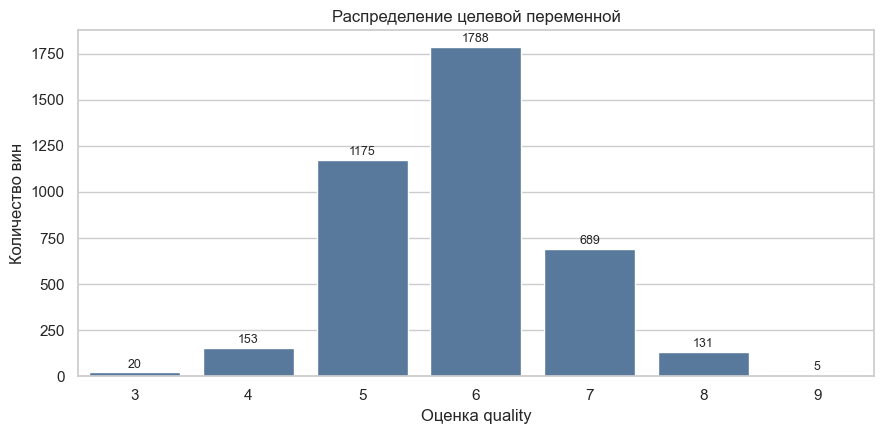

In [23]:
quality_counts = df["quality"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(x=quality_counts.index, y=quality_counts.values, color="#4C78A8", ax=ax)
ax.set(title="Распределение целевой переменной", xlabel="Оценка quality", ylabel="Количество вин")
for i, value in enumerate(quality_counts.values):
    ax.text(i, value + quality_counts.max() * 0.015, str(value), ha="center", fontsize=9)
plt.tight_layout()
plt.show()

**Вывод.** Большинство объектов имеет средние оценки 5–7, а крайние оценки встречаются редко. Функция потерь в основном оптимизируется на массовых значениях, поэтому модель может «стягивать» прогнозы редких плохих и отличных вин к среднему. Стратификация при разбиении поможет сохранить доли оценок, но не устранит нехватку редких наблюдений.

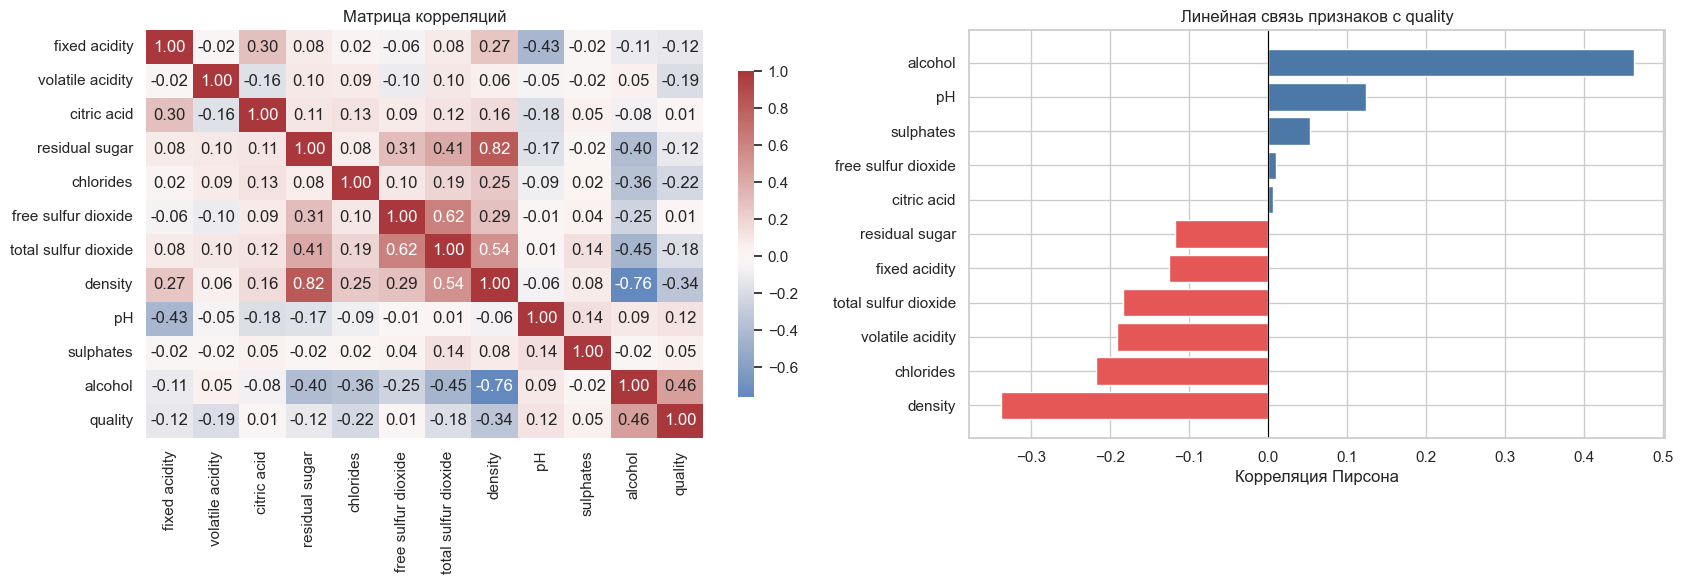

In [24]:
corr = df.corr(numeric_only=True)
quality_corr = corr["quality"].drop("quality").sort_values()

fig, axes = plt.subplots(1, 2, figsize=(17, 6))
sns.heatmap(corr, cmap="vlag", center=0, annot=True, fmt=".2f", ax=axes[0], cbar_kws={"shrink": 0.8})
axes[0].set_title("Матрица корреляций")
colors = ["#E45756" if x < 0 else "#4C78A8" for x in quality_corr.values]
axes[1].barh(quality_corr.index, quality_corr.values, color=colors)
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set(title="Линейная связь признаков с quality", xlabel="Корреляция Пирсона")
plt.tight_layout()
plt.show()

**Вывод.** Наиболее заметная положительная линейная связь ожидается у `alcohol`: более крепкие вина в среднем получают более высокую оценку. `density`, `chlorides` и `volatile acidity` обычно связаны с оценкой отрицательно. При этом отдельные корреляции умеренные, поэтому одного признака недостаточно. Сильная взаимная связь `density`, `residual sugar` и `alcohol` означает, что коэффициенты линейной модели следует трактовать осторожно: они описывают частный вклад при фиксированных остальных признаках и могут быть нестабильны из-за мультиколлинеарности.

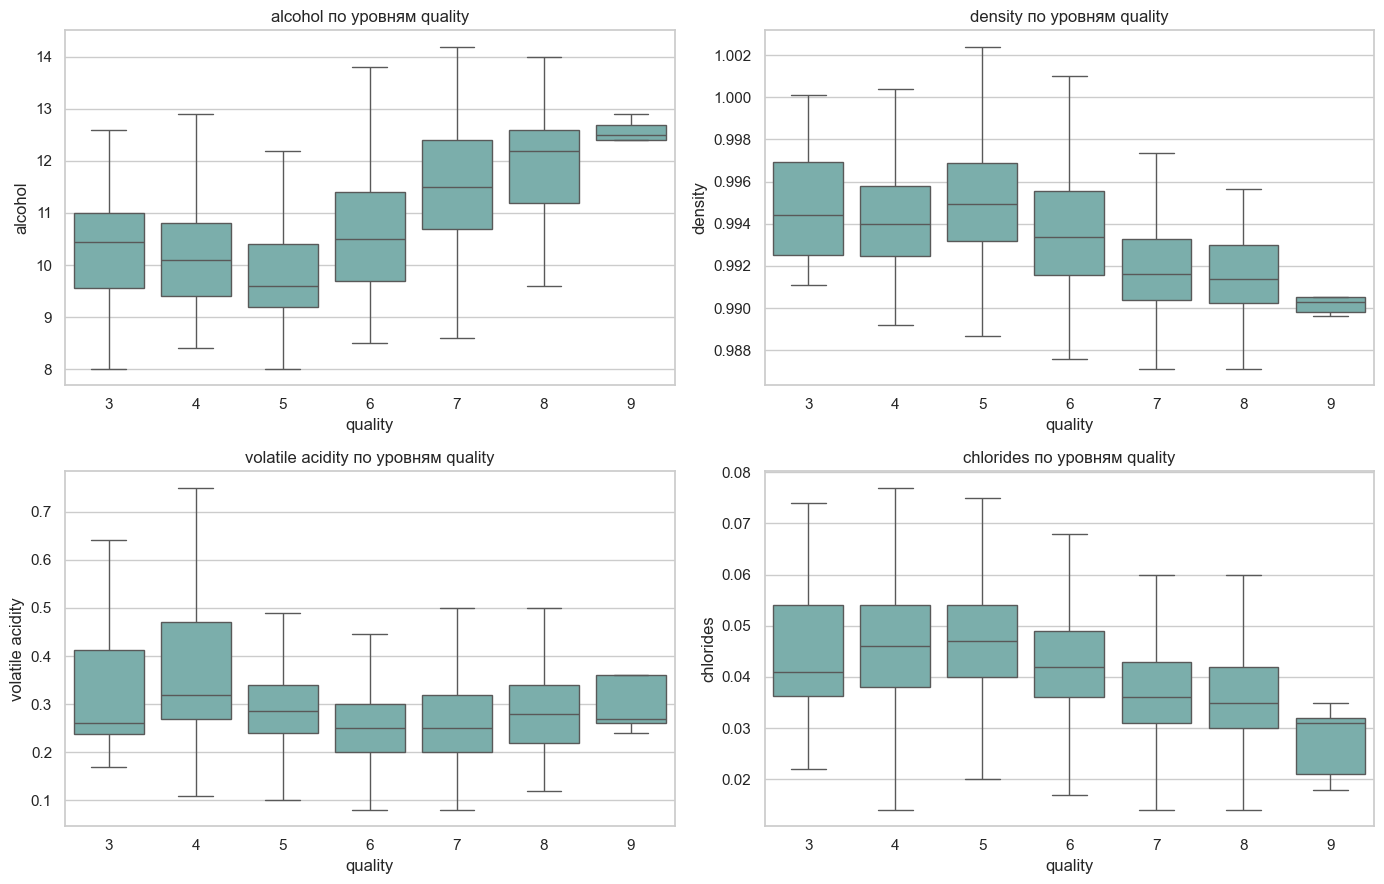

In [28]:
selected = ["alcohol", "density", "volatile acidity", "chlorides"]
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for feature, ax in zip(selected, axes.flat):
    sns.boxplot(data=df, x="quality", y=feature, color="#72B7B2", showfliers=False, ax=ax)
    ax.set_title(f"{feature} по уровням quality")
plt.tight_layout()
plt.show()

**Вывод.** Групповые распределения подтверждают общие тенденции корреляции, но сильно перекрываются. Например, высокий `alcohol` повышает вероятность хорошей оценки, однако сам по себе не определяет качество. Это аргумент в пользу многомерных моделей и возможных нелинейных взаимодействий.

## 3. Подготовка выборок

Используется разбиение 80/20: обучающая часть достаточно велика для моделей и кросс-валидации, а тестовая содержит достаточно объектов для устойчивой финальной оценки. Поскольку `quality` — дискретная порядковая оценка с редкими классами, применяем `stratify=y`, чтобы сохранить их доли. `random_state=42` фиксирует эксперимент.

Тестовая выборка ниже используется **только один раз** — после выбора гиперпараметров по кросс-валидации на обучающей части. Многократный выбор решений по результату на одном тесте приводит к скрытому переобучению на тест: оценка становится оптимистичной и хуже переносится на новые данные.

In [25]:
X = df.drop(columns="quality")
y = df["quality"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)

split_report = pd.DataFrame({
    "n": [len(X_train), len(X_test)],
    "share": [len(X_train) / len(X), len(X_test) / len(X)],
    "quality_mean": [y_train.mean(), y_test.mean()],
    "quality_std": [y_train.std(), y_test.std()],
}, index=["train", "test"])

## 4. Метрики и baseline

- **MAE** — средний модуль ошибки в единицах `quality`. Все ошибки входят линейно, поэтому метрика легко интерпретируется и сравнительно устойчива к редким крупным промахам.
- **RMSE** — квадратный корень из средней квадратичной ошибки. Возведение в квадрат сильнее штрафует большие ошибки: ошибка 2 даёт вклад 4, а ошибка 1 — вклад 1.
- Поэтому RMSE всегда не меньше MAE и заметно превышает MAE, когда распределение ошибок имеет тяжёлые хвосты или присутствуют отдельные крупные промахи.

Для константного baseline используем среднее `quality` **только по обучающей выборке**: именно среднее минимизирует сумму квадратов ошибок и, следовательно, RMSE.

In [26]:
def metrics(y_true, y_pred):
    return {
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "MAE": float(mean_absolute_error(y_true, y_pred)),
    }

baseline_constant = y_train.mean()
baseline_pred = np.full(len(y_test), baseline_constant)
print(f"Константа baseline: {baseline_constant:.3f}")
print("Метрики baseline:", {k: round(v, 3) for k, v in metrics(y_test, baseline_pred).items()})

Константа baseline: 5.855
Метрики baseline: {'RMSE': 0.891, 'MAE': 0.679}


## 5. Обучение моделей без подсматривания в test

Гиперпараметры леса и бустинга выбираются 3-фолд кросс-валидацией только на `train`. Для линейной регрессии масштабирование встроено в `Pipeline`, поэтому среднее и стандартное отклонение вычисляются заново внутри каждого фолда и утечки нет. Масштабирование не требуется деревьям, но необходимо для сопоставимой интерпретации коэффициентов линейной модели.

In [29]:
cv = KFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
scoring = "neg_root_mean_squared_error"

linear_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression()),
])
linear_cv_rmse = -cross_val_score(
    linear_model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1
).mean()
linear_model.fit(X_train, y_train)

rf_search = GridSearchCV(
    RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
    param_grid={
        "n_estimators": [300],
        "max_depth": [None],
        "min_samples_leaf": [1, 2],
        "max_features": [0.7, 1.0],
    },
    scoring=scoring, cv=cv, n_jobs=-1, refit=True,
)

gb_search = GridSearchCV(
    GradientBoostingRegressor(random_state=RANDOM_STATE),
    param_grid={
        "n_estimators": [150, 250],
        "learning_rate": [0.05],
        "max_depth": [2, 3],
        "min_samples_leaf": [3],
    },
    scoring=scoring, cv=cv, n_jobs=-1, refit=True,
)

for search in (rf_search, gb_search):
    search.fit(X_train, y_train)

cv_summary = pd.DataFrame({
    "LinearRegression": {"CV_RMSE": linear_cv_rmse, "best_params": "standardized OLS"},
    "RandomForest": {"CV_RMSE": -rf_search.best_score_, "best_params": rf_search.best_params_},
    "GradientBoosting": {"CV_RMSE": -gb_search.best_score_, "best_params": gb_search.best_params_},
}).T.sort_values("CV_RMSE")
display(cv_summary)

/Users/stillrobert/Documents/ChatGPT/Mutual/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/stillrobert/Documents/ChatGPT/Mutual/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/stillrobert/Documents/ChatGPT/Mutual/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/stillrobert/Documents/ChatGPT/Mutual/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/stillrobert/Documents/ChatGPT/Mutual/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept

,CV_RMSE,best_params
RandomForest,0.705,"{'max_depth': None, 'max_features': 0.7, 'min_..."
GradientBoosting,0.716,"{'learning_rate': 0.05, 'max_depth': 3, 'min_s..."
LinearRegression,0.747,standardized OLS


## 6. Единая финальная оценка на test

После завершения выбора параметров фиксируем модели и один раз считаем тестовые метрики в одинаковых условиях.

In [27]:
fitted_models = {
    "LinearRegression": linear_model,
    "RandomForest": rf_search.best_estimator_,
    "GradientBoosting": gb_search.best_estimator_,
}

predictions = {name: model.predict(X_test) for name, model in fitted_models.items()}
rows = [{"Модель": "Baseline", **metrics(y_test, baseline_pred)}]
rows += [{"Модель": name, **metrics(y_test, pred)} for name, pred in predictions.items()]
results = pd.DataFrame(rows).set_index("Модель").sort_values("RMSE")
results["Лучше baseline"] = results["RMSE"] < results.loc["Baseline", "RMSE"]
results["RMSE < 0.70"] = results["RMSE"] < 0.70
display(results)

,RMSE,MAE,Лучше baseline,RMSE < 0.70
Модель,,,,
RandomForest,0.692,0.536,True,True
GradientBoosting,0.709,0.554,True,False
LinearRegression,0.761,0.587,True,False
Baseline,0.891,0.679,False,False


In [13]:
baseline_rmse = results.loc["Baseline", "RMSE"]
for name in ["LinearRegression", "RandomForest", "GradientBoosting"]:
    gain = 100 * (baseline_rmse - results.loc[name, "RMSE"]) / baseline_rmse
    print(f"{name}: RMSE ниже baseline на {gain:.1f}%")

LinearRegression: RMSE ниже baseline на 14.6%
RandomForest: RMSE ниже baseline на 22.3%
GradientBoosting: RMSE ниже baseline на 20.4%


**Интерпретация сравнения.** Если деревья превосходят линейную регрессию, это согласуется с EDA: зависимости между физико-химическими показателями и экспертной оценкой не обязаны быть линейными, а признаки взаимодействуют. Random Forest снижает дисперсию усреднением множества деревьев и хорошо ловит локальные нелинейности. Gradient Boosting последовательно исправляет ошибки предыдущих деревьев и часто даёт более гладкое приближение.

## 7. Коэффициенты Linear Regression

Поскольку признаки стандартизованы, абсолютные коэффициенты можно сопоставлять: коэффициент показывает изменение прогноза `quality` при увеличении признака на одно стандартное отклонение при прочих равных.

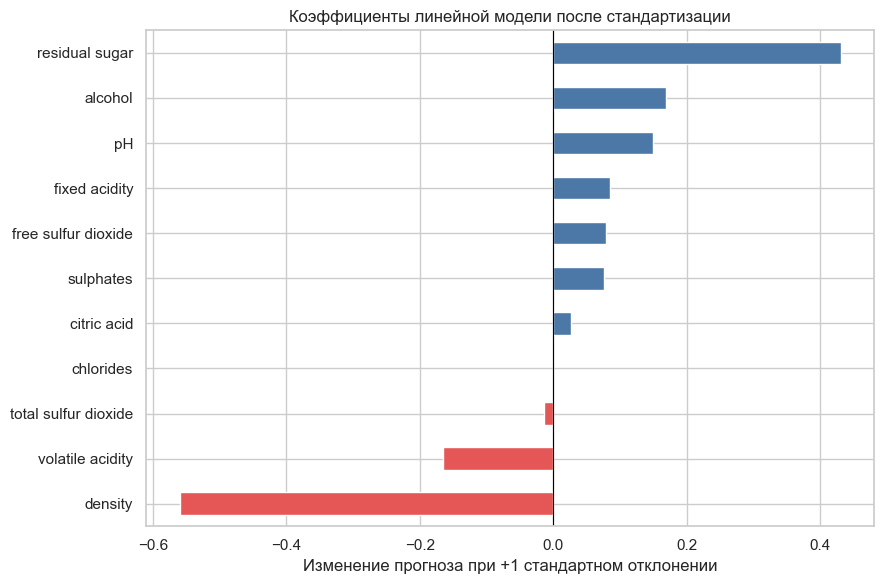

In [30]:
linear_coefs = pd.Series(
    linear_model.named_steps["model"].coef_, index=X.columns, name="coefficient"
).sort_values()
colors = ["#E45756" if value < 0 else "#4C78A8" for value in linear_coefs.values]
ax = linear_coefs.plot(kind="barh", figsize=(9, 6), color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set(title="Коэффициенты линейной модели после стандартизации", xlabel="Изменение прогноза при +1 стандартном отклонении", ylabel="")
plt.tight_layout()
plt.show()

Знак коэффициента согласуется с направлением условной линейной связи, но его нельзя читать как причинный эффект. Кроме того, коррелирующие признаки могут «делить» влияние между собой, поэтому коэффициенты следует сопоставлять с EDA и устойчивостью на новых данных.

## 8. Feature importance деревьев

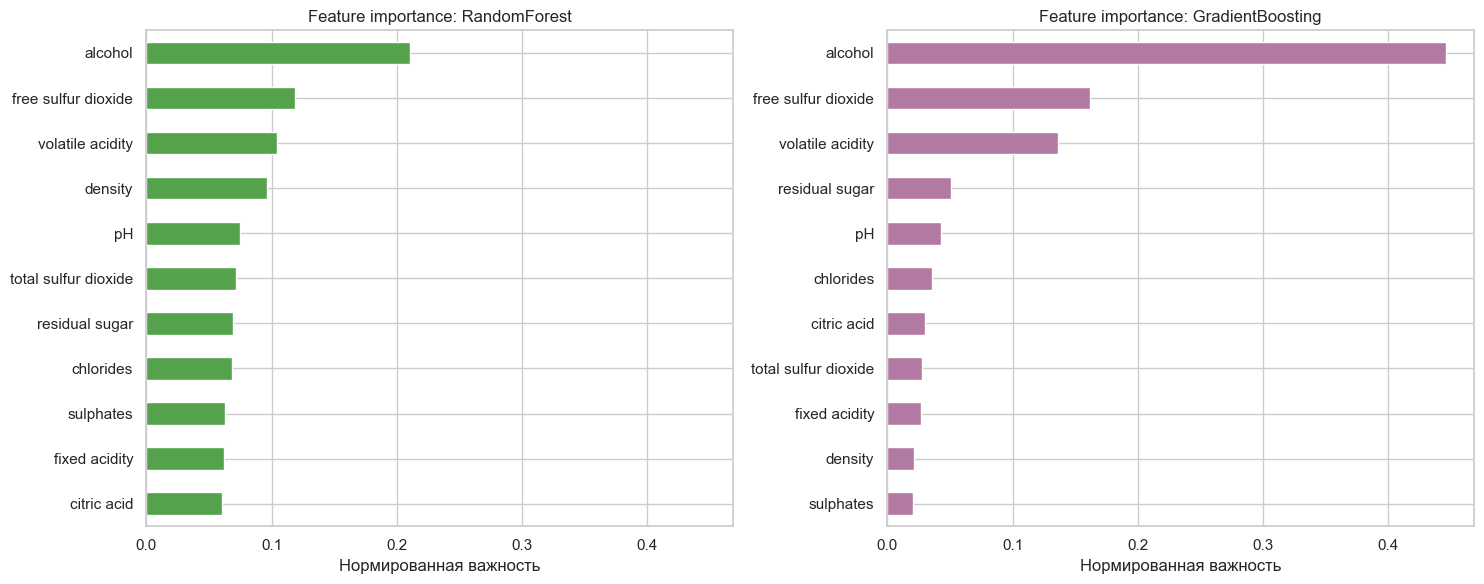

,RandomForest,GradientBoosting
alcohol,0.211,0.447
free sulfur dioxide,0.119,0.162
volatile acidity,0.105,0.136
density,0.096,0.021
pH,0.075,0.043
total sulfur dioxide,0.072,0.027
residual sugar,0.069,0.051
chlorides,0.068,0.036
sulphates,0.063,0.020
fixed acidity,0.062,0.026


Топ-5 Random Forest: ['alcohol', 'density', 'free sulfur dioxide', 'pH', 'volatile acidity']
Топ-5 Gradient Boosting: ['alcohol', 'free sulfur dioxide', 'pH', 'residual sugar', 'volatile acidity']
Общие признаки в топ-5: ['alcohol', 'free sulfur dioxide', 'pH', 'volatile acidity']


In [15]:
importance = pd.DataFrame({
    "RandomForest": fitted_models["RandomForest"].feature_importances_,
    "GradientBoosting": fitted_models["GradientBoosting"].feature_importances_,
}, index=X.columns)

fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharex=True)
for column, ax, color in zip(importance.columns, axes, ["#54A24B", "#B279A2"]):
    importance[column].sort_values().plot(kind="barh", ax=ax, color=color)
    ax.set(title=f"Feature importance: {column}", xlabel="Нормированная важность", ylabel="")
plt.tight_layout()
plt.show()

display(importance.sort_values("RandomForest", ascending=False))
top_rf = set(importance["RandomForest"].nlargest(5).index)
top_gb = set(importance["GradientBoosting"].nlargest(5).index)
print("Топ-5 Random Forest:", sorted(top_rf))
print("Топ-5 Gradient Boosting:", sorted(top_gb))
print("Общие признаки в топ-5:", sorted(top_rf & top_gb))

**Сопоставление.** Если `alcohol` занимает высокое место, результат согласуется с корреляционным анализом. Деревья также могут выделить признаки с небольшой линейной корреляцией, если их эффект нелинеен или проявляется во взаимодействии. Различия между лесом и бустингом естественны: лес усредняет независимые деревья, а бустинг концентрируется на исправлении остаточных ошибок.

Feature importance **не доказывает причинность**. Она показывает, насколько модель использовала признак для уменьшения ошибки в наблюдательных данных. Важность может отражать корреляцию, общий скрытый фактор, смещение выборки или делиться между взаимосвязанными признаками. Для причинного вывода нужен отдельный дизайн исследования или эксперимент.

## 9. Анализ ошибок лучшей модели

Лучшая модель на финальном тесте: RandomForest
RMSE=0.692, MAE=0.536


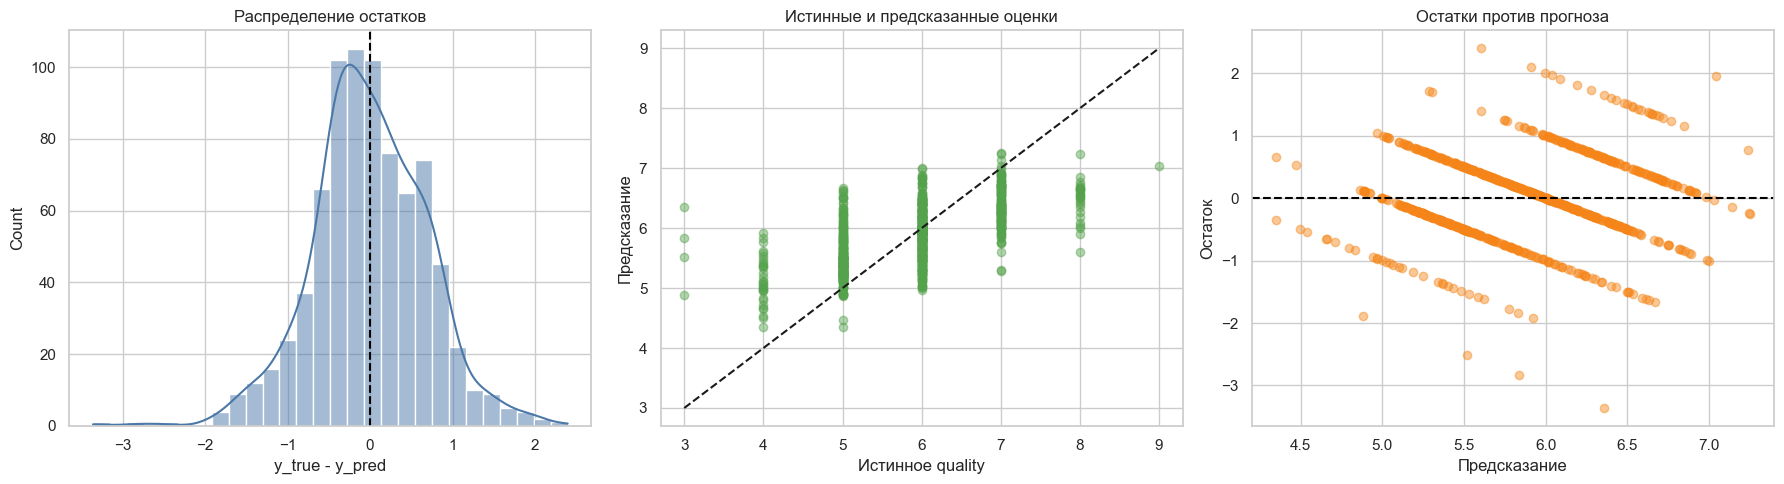

In [16]:
best_name = results.drop(index="Baseline")["RMSE"].idxmin()
best_pred = predictions[best_name]
residuals = y_test.to_numpy() - best_pred

print(f"Лучшая модель на финальном тесте: {best_name}")
print(f"RMSE={results.loc[best_name, 'RMSE']:.3f}, MAE={results.loc[best_name, 'MAE']:.3f}")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.histplot(residuals, bins=28, kde=True, color="#4C78A8", ax=axes[0])
axes[0].axvline(0, color="black", linestyle="--")
axes[0].set(title="Распределение остатков", xlabel="y_true - y_pred")

axes[1].scatter(y_test, best_pred, alpha=0.45, color="#54A24B")
limits = [min(y_test.min(), best_pred.min()), max(y_test.max(), best_pred.max())]
axes[1].plot(limits, limits, "k--")
axes[1].set(title="Истинные и предсказанные оценки", xlabel="Истинное quality", ylabel="Предсказание")

axes[2].scatter(best_pred, residuals, alpha=0.45, color="#F58518")
axes[2].axhline(0, color="black", linestyle="--")
axes[2].set(title="Остатки против прогноза", xlabel="Предсказание", ylabel="Остаток")
plt.tight_layout()
plt.show()

,n,MAE,bias_true_minus_pred,RMSE
quality,,,,
3,4,2.649,-2.649,2.703
4,31,1.141,-1.141,1.208
5,235,0.537,-0.520,0.654
6,358,0.343,0.092,0.426
7,138,0.640,0.631,0.721
8,26,1.538,1.538,1.574
9,1,1.957,1.957,1.957


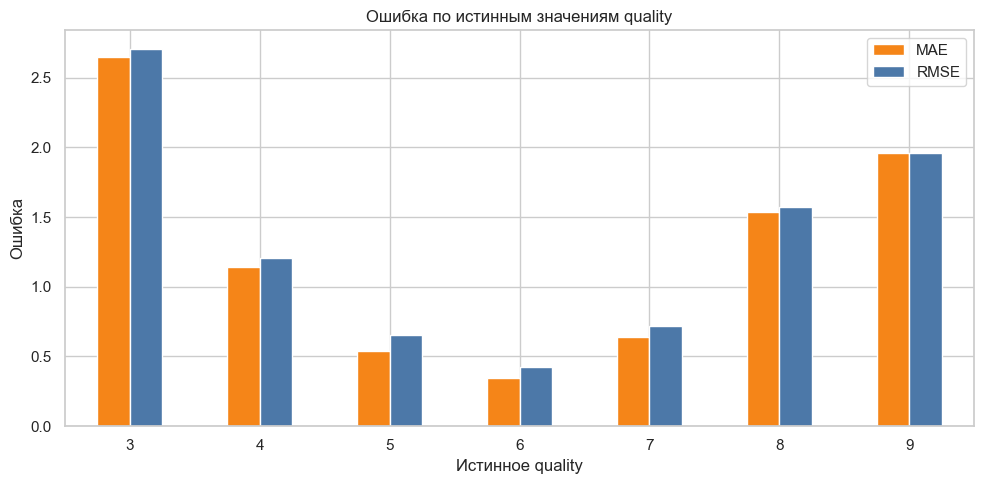

In [17]:
error_frame = pd.DataFrame({
    "quality": y_test.to_numpy(),
    "prediction": best_pred,
    "residual": residuals,
})
error_frame["abs_error"] = error_frame["residual"].abs()
error_frame["sq_error"] = error_frame["residual"] ** 2

error_by_quality = error_frame.groupby("quality").agg(
    n=("residual", "size"),
    MAE=("abs_error", "mean"),
    MSE=("sq_error", "mean"),
    bias_true_minus_pred=("residual", "mean"),
)
error_by_quality["RMSE"] = np.sqrt(error_by_quality.pop("MSE"))
display(error_by_quality)

fig, ax1 = plt.subplots(figsize=(10, 5))
error_by_quality[["MAE", "RMSE"]].plot(kind="bar", ax=ax1, color=["#F58518", "#4C78A8"])
ax1.set(title="Ошибка по истинным значениям quality", xlabel="Истинное quality", ylabel="Ошибка")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [18]:
worst_positions = np.argsort(np.abs(residuals))[::-1][:10]
worst = X_test.iloc[worst_positions].copy()
worst.insert(0, "true_quality", y_test.iloc[worst_positions].to_numpy())
worst.insert(1, "prediction", best_pred[worst_positions])
worst.insert(2, "residual", residuals[worst_positions])
worst.insert(3, "abs_error", np.abs(residuals[worst_positions]))
display(worst.round(3))

,true_quality,prediction,residual,abs_error,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
1037,3,6.360,-3.360,3.360,8.300,0.330,0.420,1.150,0.033,18.000,96.000,0.991,3.200,0.320,12.400
2535,3,5.840,-2.840,2.840,6.100,0.200,0.340,9.500,0.041,38.000,201.000,0.995,3.140,0.440,10.100
1424,3,5.517,-2.517,2.517,6.700,0.250,0.260,1.550,0.041,118.500,216.000,0.995,3.550,0.630,9.400
215,8,5.603,2.397,2.397,6.700,0.260,0.390,1.100,0.040,45.000,147.000,0.994,3.320,0.580,9.600
2097,8,5.910,2.090,2.090,7.300,0.170,0.240,8.100,0.121,32.000,162.000,0.995,3.170,0.380,10.400
658,8,5.997,2.003,2.003,8.100,0.170,0.440,14.100,0.053,43.000,145.000,1.001,3.280,0.750,8.800
724,8,6.037,1.963,1.963,7.800,0.180,0.460,12.600,0.042,41.000,143.000,1.000,3.240,0.760,8.500
732,9,7.043,1.957,1.957,6.900,0.360,0.340,4.200,0.018,57.000,119.000,0.990,3.280,0.360,12.700
1847,4,5.920,-1.920,1.920,7.600,0.230,0.260,15.300,0.067,32.000,166.000,0.999,3.030,0.440,9.200
2466,8,6.090,1.910,1.910,6.500,0.350,0.360,0.800,0.034,32.000,111.000,0.989,3.110,0.500,12.100


**Разбор ошибок.** На графике истинных и предсказанных значений обычно заметно стягивание прогнозов к центру: низкие оценки завышаются, а высокие занижаются. Причина — дисбаланс `quality` и оптимизация средней ошибки: для редких крайних значений у модели мало примеров, а усреднение в листьях деревьев дополнительно сглаживает прогноз.

Крупные ошибки в таблице могут возникать у объектов, чьи физико-химические показатели похожи на массовые вина средней оценки, но экспертная оценка оказалась крайней. Набор не содержит потенциально важных факторов — сорта винограда, производителя, года, условий хранения и индивидуальных оценок дегустаторов. Поэтому часть вариативности `quality` принципиально не объясняется доступными признаками.

## 10. Итоговый вывод

In [19]:
best_rmse = results.loc[best_name, "RMSE"]
best_mae = results.loc[best_name, "MAE"]
improvement = 100 * (baseline_rmse - best_rmse) / baseline_rmse
target_status = "достигнут" if best_rmse < 0.70 else "не достигнут"

print(f"Лучшая модель: {best_name}.")
print(f"Тестовые RMSE={best_rmse:.3f}, MAE={best_mae:.3f}.")
print(f"Улучшение RMSE относительно baseline: {improvement:.1f}%.")
print(f"Требуемый порог RMSE < 0.70 {target_status}.")
print("Все решения по параметрам приняты без использования ответов тестовой выборки.")

Лучшая модель: RandomForest.
Тестовые RMSE=0.692, MAE=0.536.
Улучшение RMSE относительно baseline: 22.3%.
Требуемый порог RMSE < 0.70 достигнут.
Все решения по параметрам приняты без использования ответов тестовой выборки.
